# Beamforming with an uncertain spatial subspace

**What does a distribution add beyond its modal subspace, and when is it worth computing?**

We start with the observed array snapshots, make the posterior geometry visible, then examine the beamformer and independent benchmarks. The main study uses native complex lines at $N=8$ and $N=16$; the final experiment measures rank-one computations through $N=128$. A three-dimensional drawing of a high-dimensional posterior will always be labelled as a section, rather than presented as the whole state space.

This notebook follows the attached draft's theory and notation. Its proper-complex beamforming likelihood is a stated extension of the draft's real marginal model. The earlier executed beamforming study, including its different stochastic-process and parameter-inference experiments, is preserved in the [historical notebook](../results/simulation_redesign/archive/01_array_2a8697c.ipynb).

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'lib').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from lib.plotting import plt
from lib.simulation_story_visuals import load_studies
from lib.simulation_validation import verify_legacy
from scripts.make_geometry_notebooks import verify_summary
D = load_studies(ROOT, 'paper')
from lib.simulation_validation import require_gate
SUMMARY = verify_summary(require_gate(ROOT))
BASE = D['base']
F = BASE / 'figures'
FIG = json.loads((F / 'manifest.json').read_text())
assert FIG['profile'] == 'paper'
assert plt.rcParams['text.usetex'] is True
assert plt.rcParams['figure.dpi'] == plt.rcParams['savefig.dpi'] == 200
for mapping in ('sources', 'input_manifests'):
    for name, expected in FIG[mapping].items():
        assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == expected

def show(name):
    path = F / (name + '.png')
    assert hashlib.sha256(path.read_bytes()).hexdigest() == FIG['files'][path.name]
    display(Image(filename=str(path), width=1400))
    display(Markdown(FIG['captions'][name]))

print('Verified the current theory gate, four paper components, figures and findings.')

Verified the current theory gate, four paper components, figures and findings.


## B1. What is measured?

The array observes $u_t=h_tz_t+e_t$, with $\|h_t\|=1$, $z_t\sim\mathcal{CN}(0,\tau^2)$ and $e_t\sim\mathcal{CN}(0,sI)$. Integrating the unknown coefficient gives $u_t\mid\mathcal X_t\sim\mathcal{CN}(0,sI+\tau^2P_{\mathcal X_t})$. The estimator receives only the snapshots. The desired unit steering signature $a$ is supplied later, for the constraint $w^Ha=1$.

The physical array is a half-wavelength ULA. Desired/interferer separations $3^\circ,10^\circ,30^\circ$ span nearby and well-separated arrivals; a fixed Haar spatial signature is the matched ambient-prior control. All settings, independent validation/test seeds and displayed trajectories were fixed before test comparisons. Powers are variances. The desired signature is absent from posterior correction.

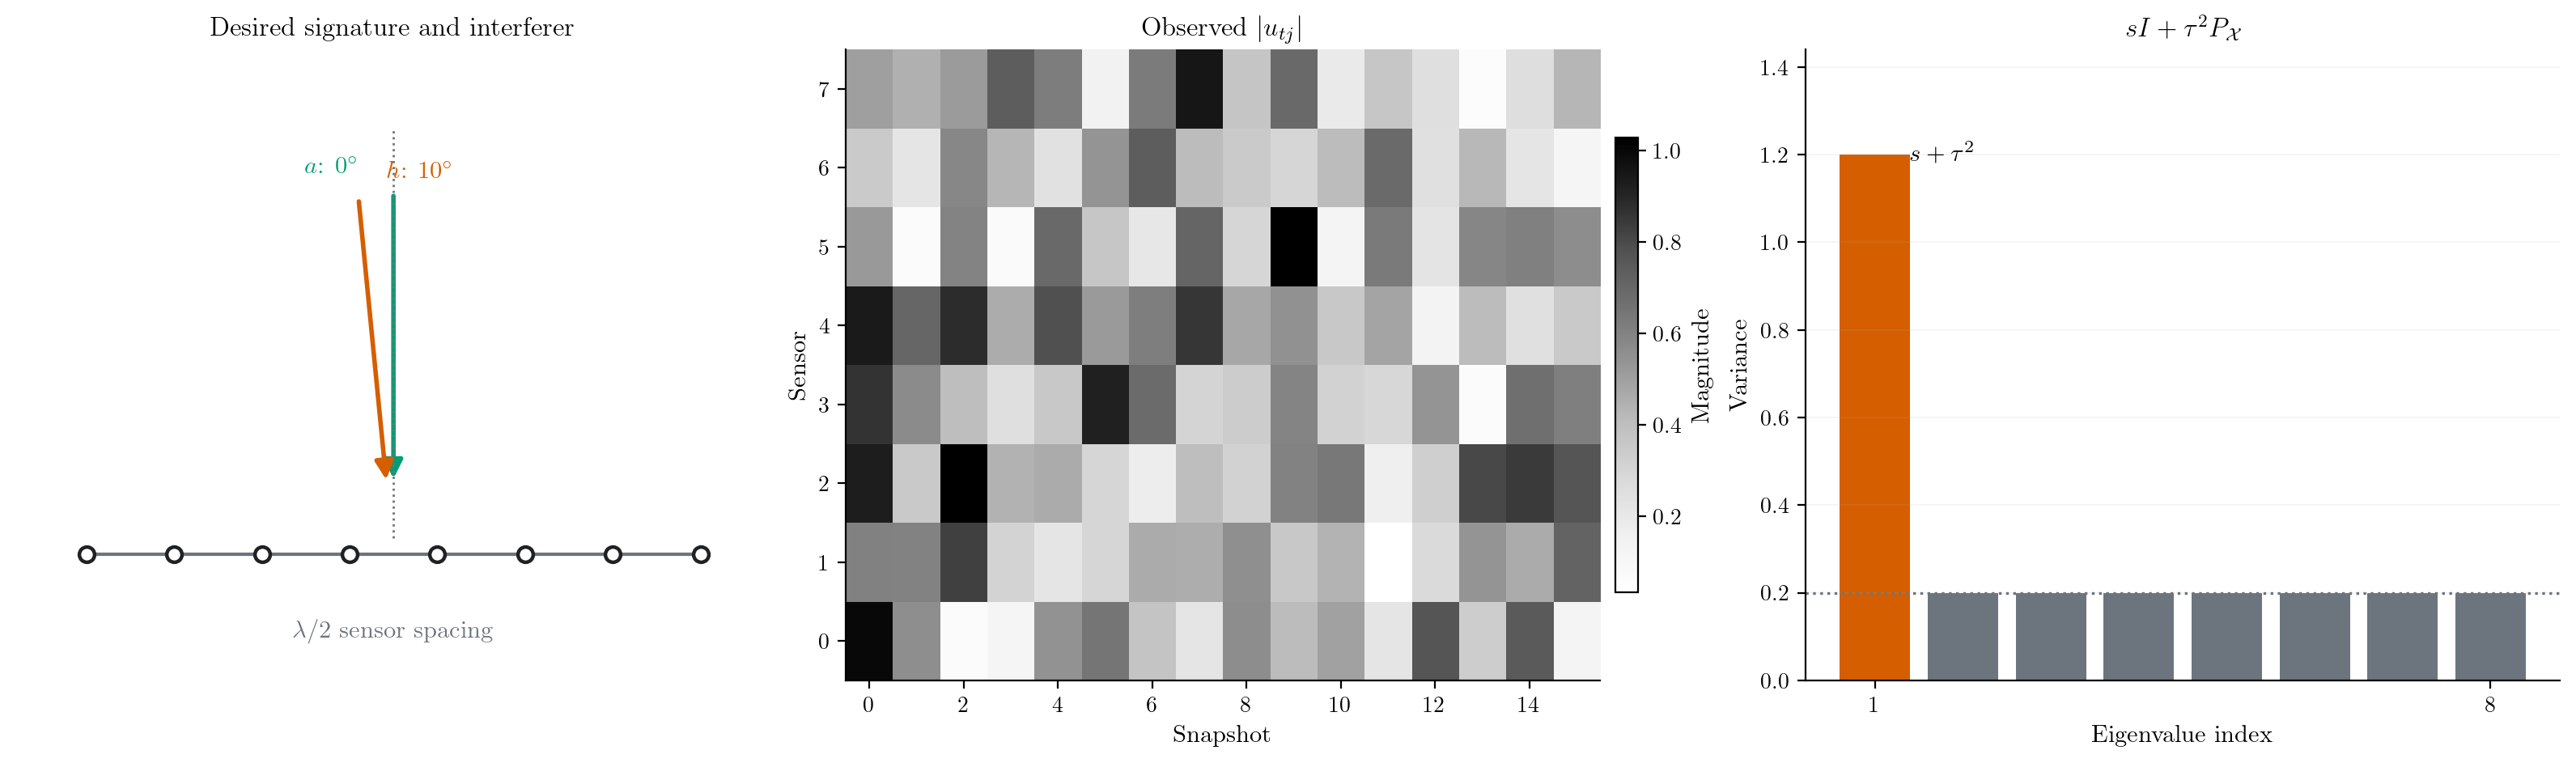

Passive interference-plus-noise snapshots identify a spatial line. The desired steering signature $a$ enters only the distortionless decision. The latent coefficients and true interferer enter generation and scoring, never estimation. Powers $s$ and $\tau^2$ are variances. The displayed ULA trajectory was fixed in advance.

In [2]:
show('beamforming_01_setup')

## B4. What does the posterior look like?

For proper-complex data, $B_t=\tau^2u_tu_t^H/[s(s+\tau^2)]$, with **no factor $1/2$**. Algorithm 1 adds this statistic once per observation and recenters the parameter to trace zero. A uniform prior and stationary $\beta=1$ make the mode the leading sample-covariance eigenspace. We write the modal projector $P_{\widehat{\mathcal X}_t}$ and full mean $\overline P_t^+=\mathbb E[P_{\mathcal X_t}\mid\mathcal D_t]$ exactly as in the draft.

The sphere below evaluates the actual density on $h=U_3x$, $x\in S^2$, where $U_3$ contains the mode and two complementary eigenvectors. It is a **real-coefficient section of a complex $N=8$ law**. The mean spectrum and all eigengaps reveal the directions that this section omits. Complex $N=2$ would map to an axially symmetric Bloch-sphere density and cannot demonstrate general directional anisotropy.

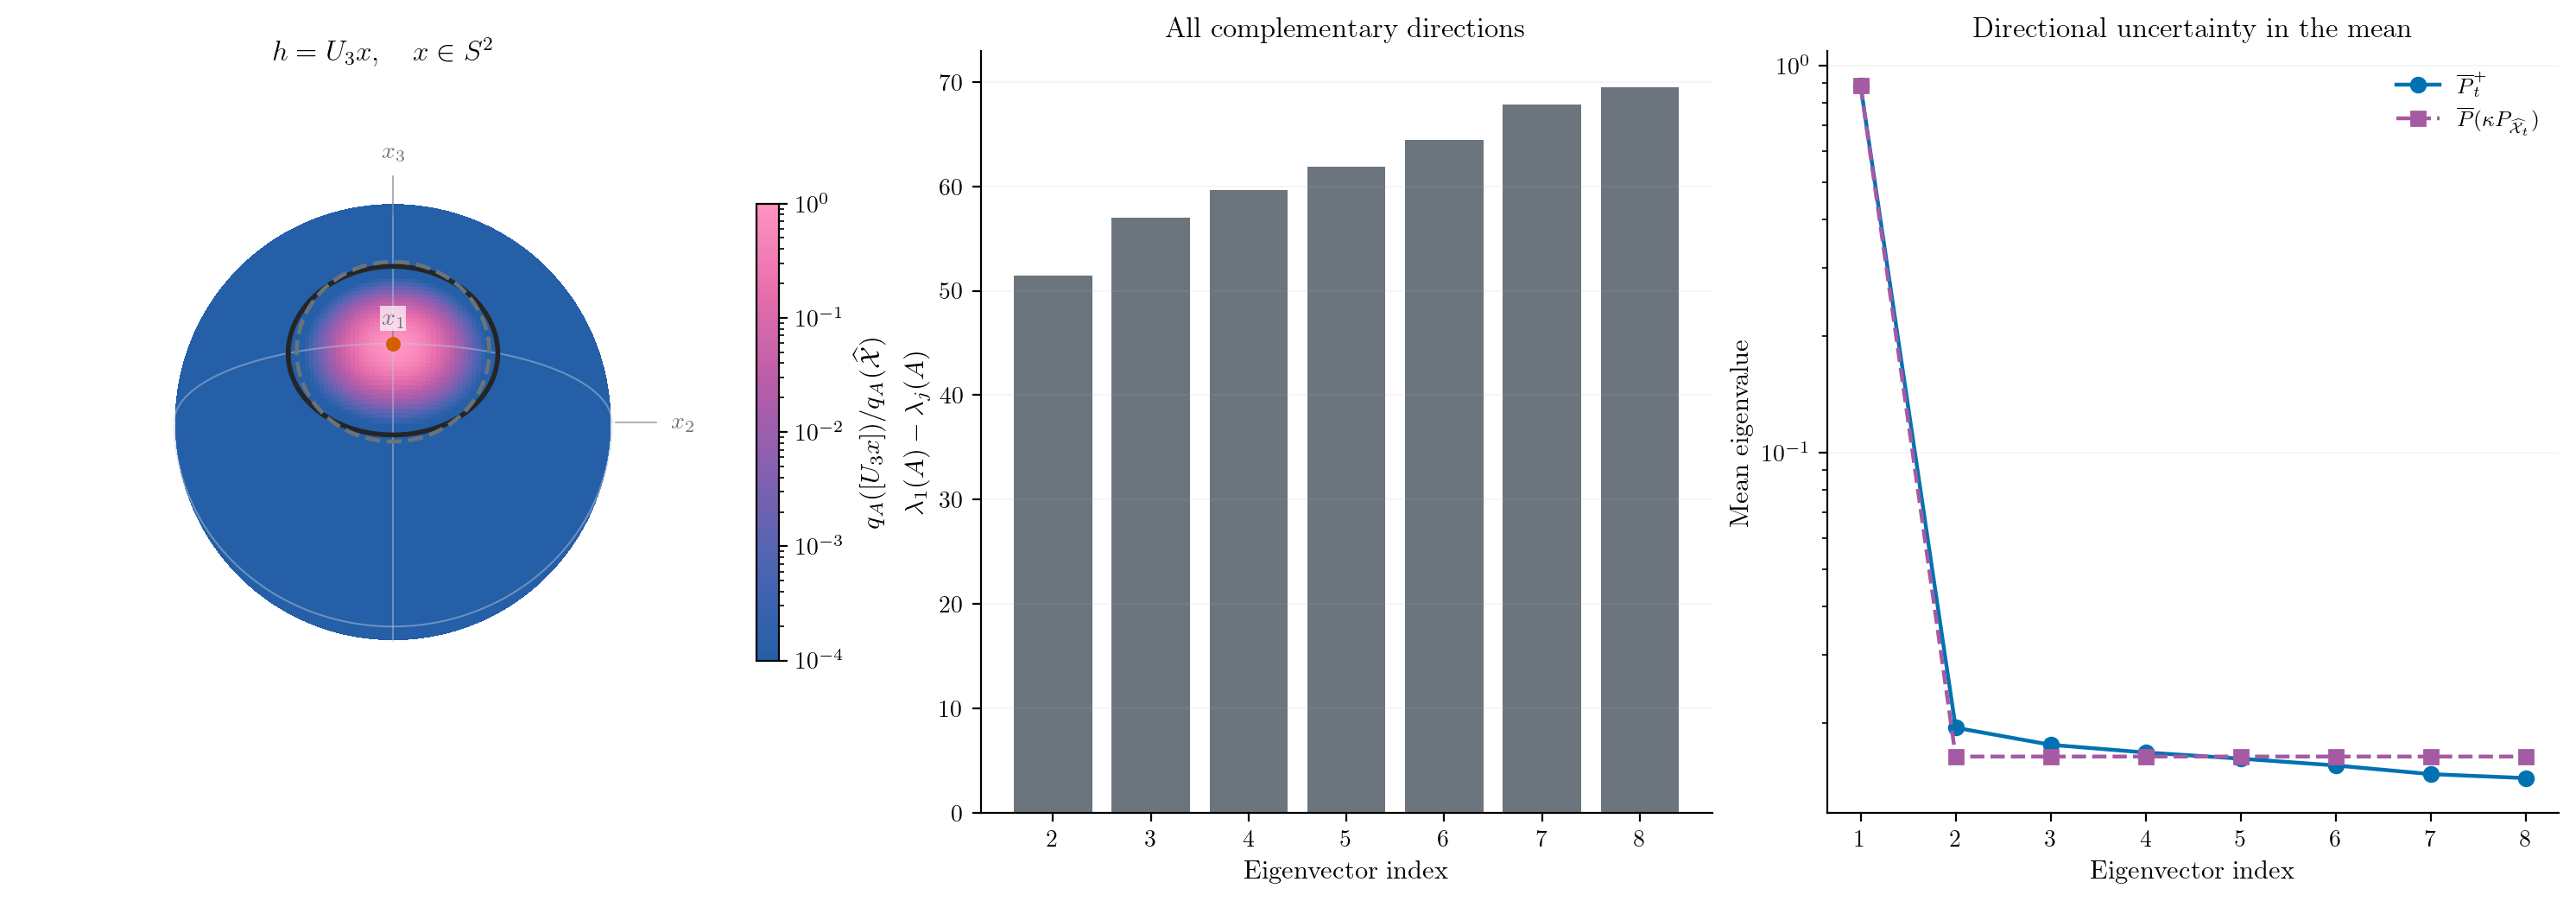

This is an actual $N=8$ proper-complex posterior at $t=16$. The sphere is the real-coefficient section $h=U_3x$, $x\in S^2$, through its mode and the least/most concentrated complementary eigenvectors. Colors are $q_A([U_3x])/q_A(\widehat{\mathcal X})$, not a normalized sphere marginal. State-region curves are intersections, not 95%-mass surface regions. All complementary gaps and all mean eigenvalues are shown alongside it.

In [3]:
show('beamforming_02_posterior')
assert D['beamforming']['shape'].pca_mode_error.max() < 1e-7

## B4. Can the mode and a radius determine a decision?

Here two selected-data posteriors have identical modes, spectra and **every** centered chordal-distance quantile. A unitary transformation fixes the mode and interchanges two complementary directions relative to the desired steering vector. Their directional mean projectors therefore differ.

For the posterior covariance $\overline R=sI+\tau^2\overline P_t^+$, the distortionless expected-power action is $w_\star=\overline R^{-1}a/(a^H\overline R^{-1}a)$. Its conditional excess identity is $(w-w_\star)^H\overline R(w-w_\star)\ge0$. The axial control $q_{\kappa P_{\widehat{\mathcal X}_t}}$ matches the modal mean overlap, hence $r_{t,\mathrm{rms}}$, without using test truth. Matching this one number does not preserve orientation-dependent predictions.

This controlled calculation illustrates information that one radius loses. It is not a claim that the Bayesian action wins on every fixed true covariance. That empirical question comes next.

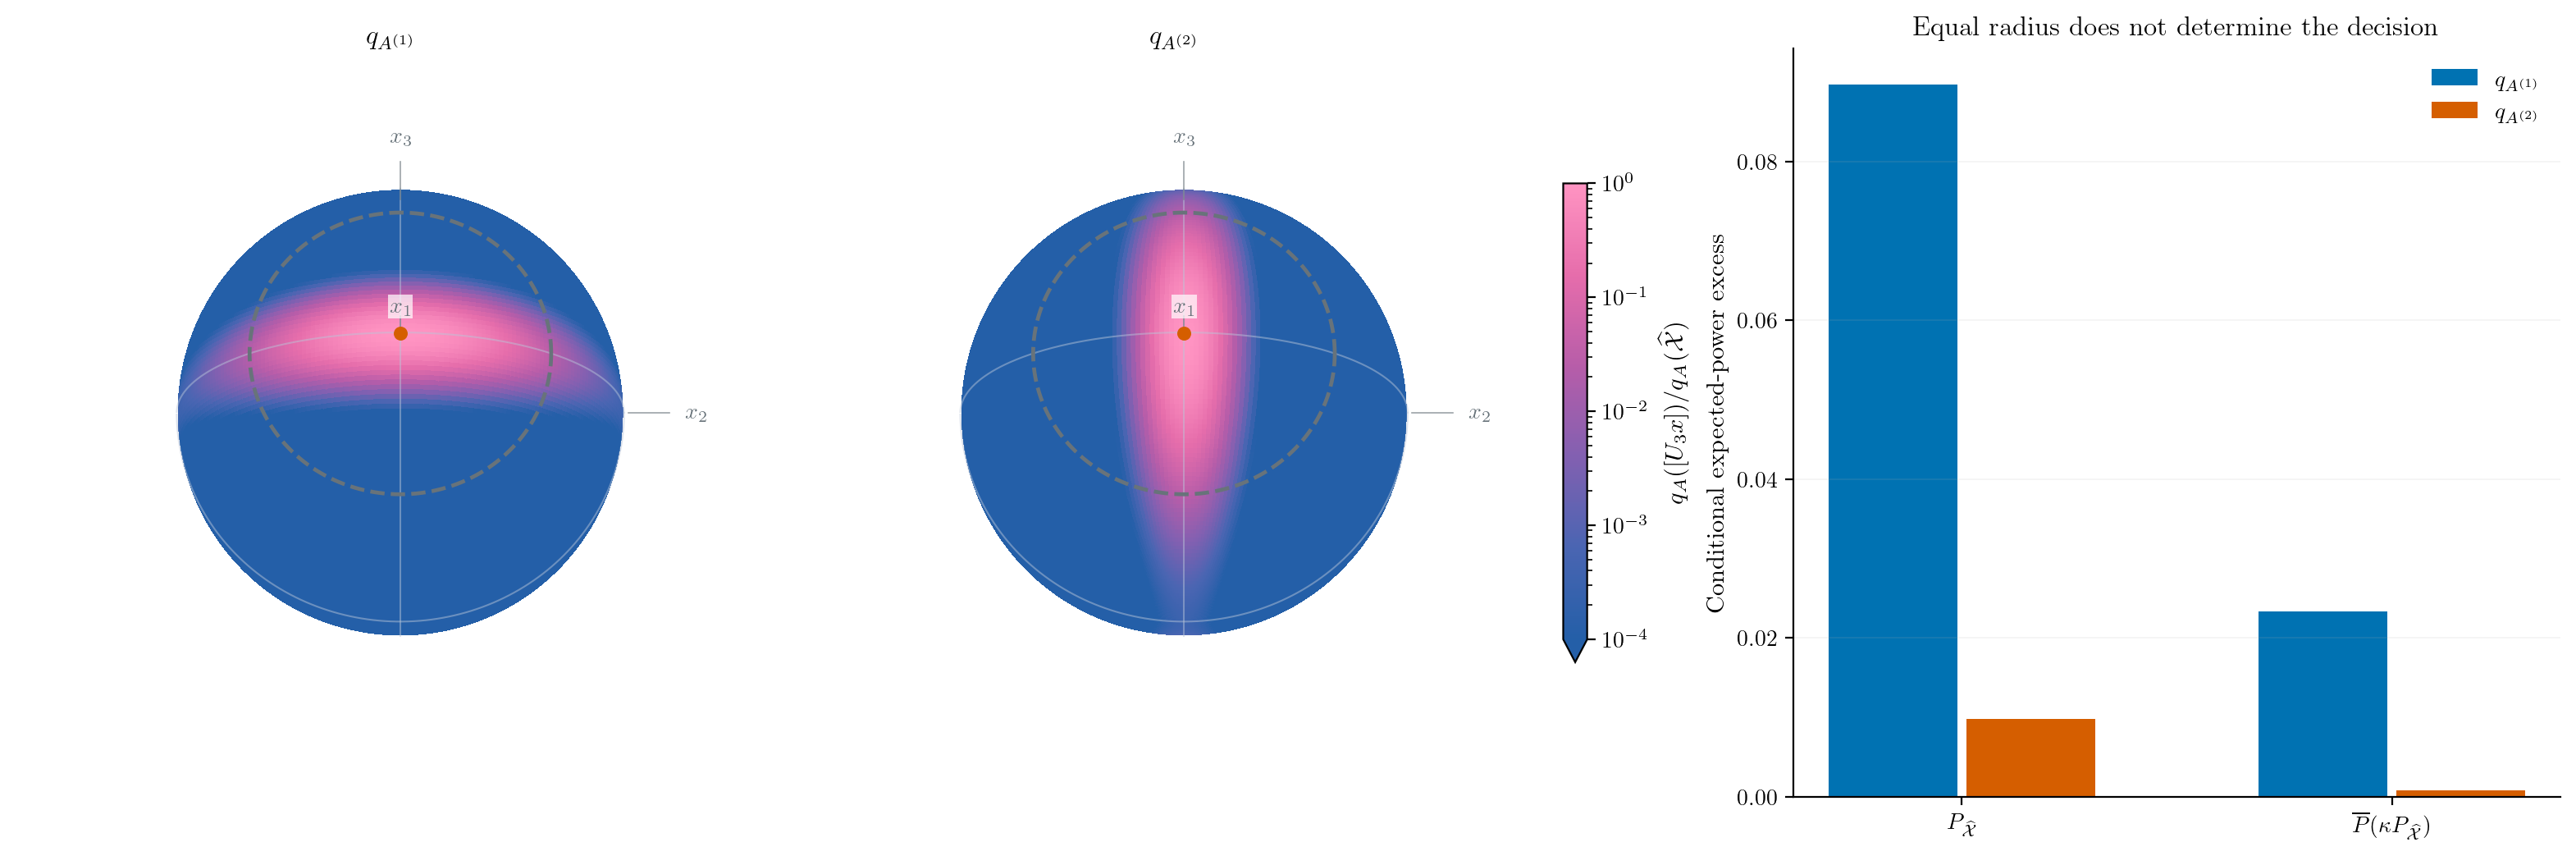

Selected-data complex beliefs have the same mode, spectrum and entire centered chordal-distance distribution, with two complementary directions interchanged relative to the fixed desired steering vector. Both spheres use one fixed $U_3$ frame; gray curves are equal-radius intersections. Conditional expected-power excess is evaluated under each stated belief and is not a repeated-training performance claim.

In [4]:
show('beamforming_03_directional')

## B5. Does it improve repeated-training performance?

Ledoit--Wolf covariance shrinkage adapts to each observed dataset. Loaded covariance and GROUSE receive independent validation choices; a regularized spectral control uses a continuously selected coefficient. These references test whether a gain over the mode can be explained by cheaper regularization. Every method sees the same training and held-out snapshots.

The paired points are independent trajectories, not steering-grid locations or posterior samples. Below the diagonal favors $\overline P_t^+$. The distribution of paired differences retains both gains and losses. The objective is output power, not expected SINR or expected log-SINR. Pointwise paired intervals and the complete comparison tables are descriptive comparisons, with no multiple-comparison guarantee.

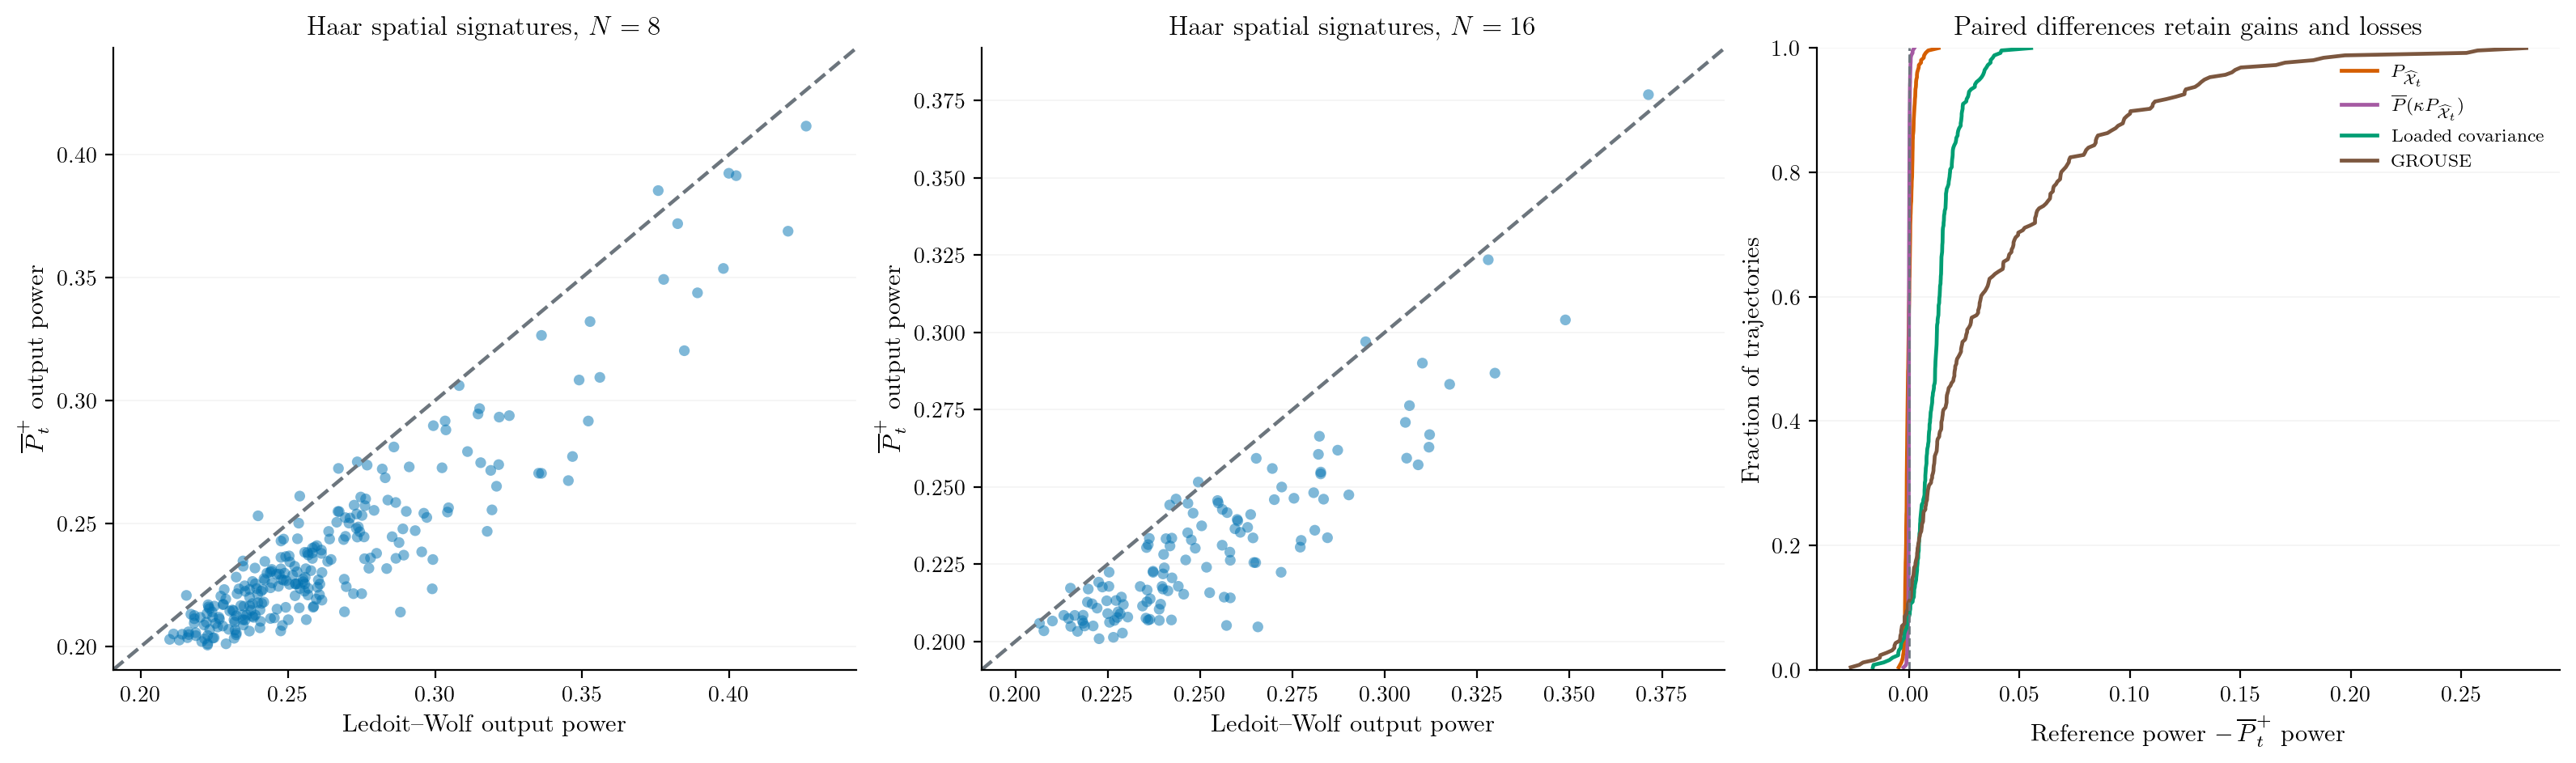

Each paired point is an independent held-out trajectory at $s=0.2$, $t=16$. Ledoit--Wolf adapts its covariance regularization to each dataset. The first two panels use Haar spatial signatures at $N=8$ and $N=16$; the final panel is the $N=8$, $10^\circ$ ULA comparison. Positive reference-minus-mean power differences favor the posterior mean. All other conditions and comparators remain in saved tables; no universal ranking is assumed.

In [5]:
show('beamforming_04_benchmarks')

## B4. What is uncertain, and where does geometry matter?

The left panel is the actual weight beampattern $|w^Ha(\theta)|^2$. The middle is the different covariance functional $s+\tau^2a(\theta)^HP_{\mathcal X}a(\theta)$, with central 50% and 95% posterior intervals. At the exact true interferer direction this functional is at its support maximum, so a finite continuous equal-tail interval excludes the endpoint. This is not a failure of the posterior sampler; arbitrary scalar intervals are not uniform frequentist confidence bands.

The small complete separation/horizon grid asks where the posterior mean improves on adaptive covariance shrinkage, including losses. It uses every predeclared physical separation at the stated noise level. A posterior action minimizes its conditional model-based loss; a fixed physical geometry can still favor a competing decision rule.

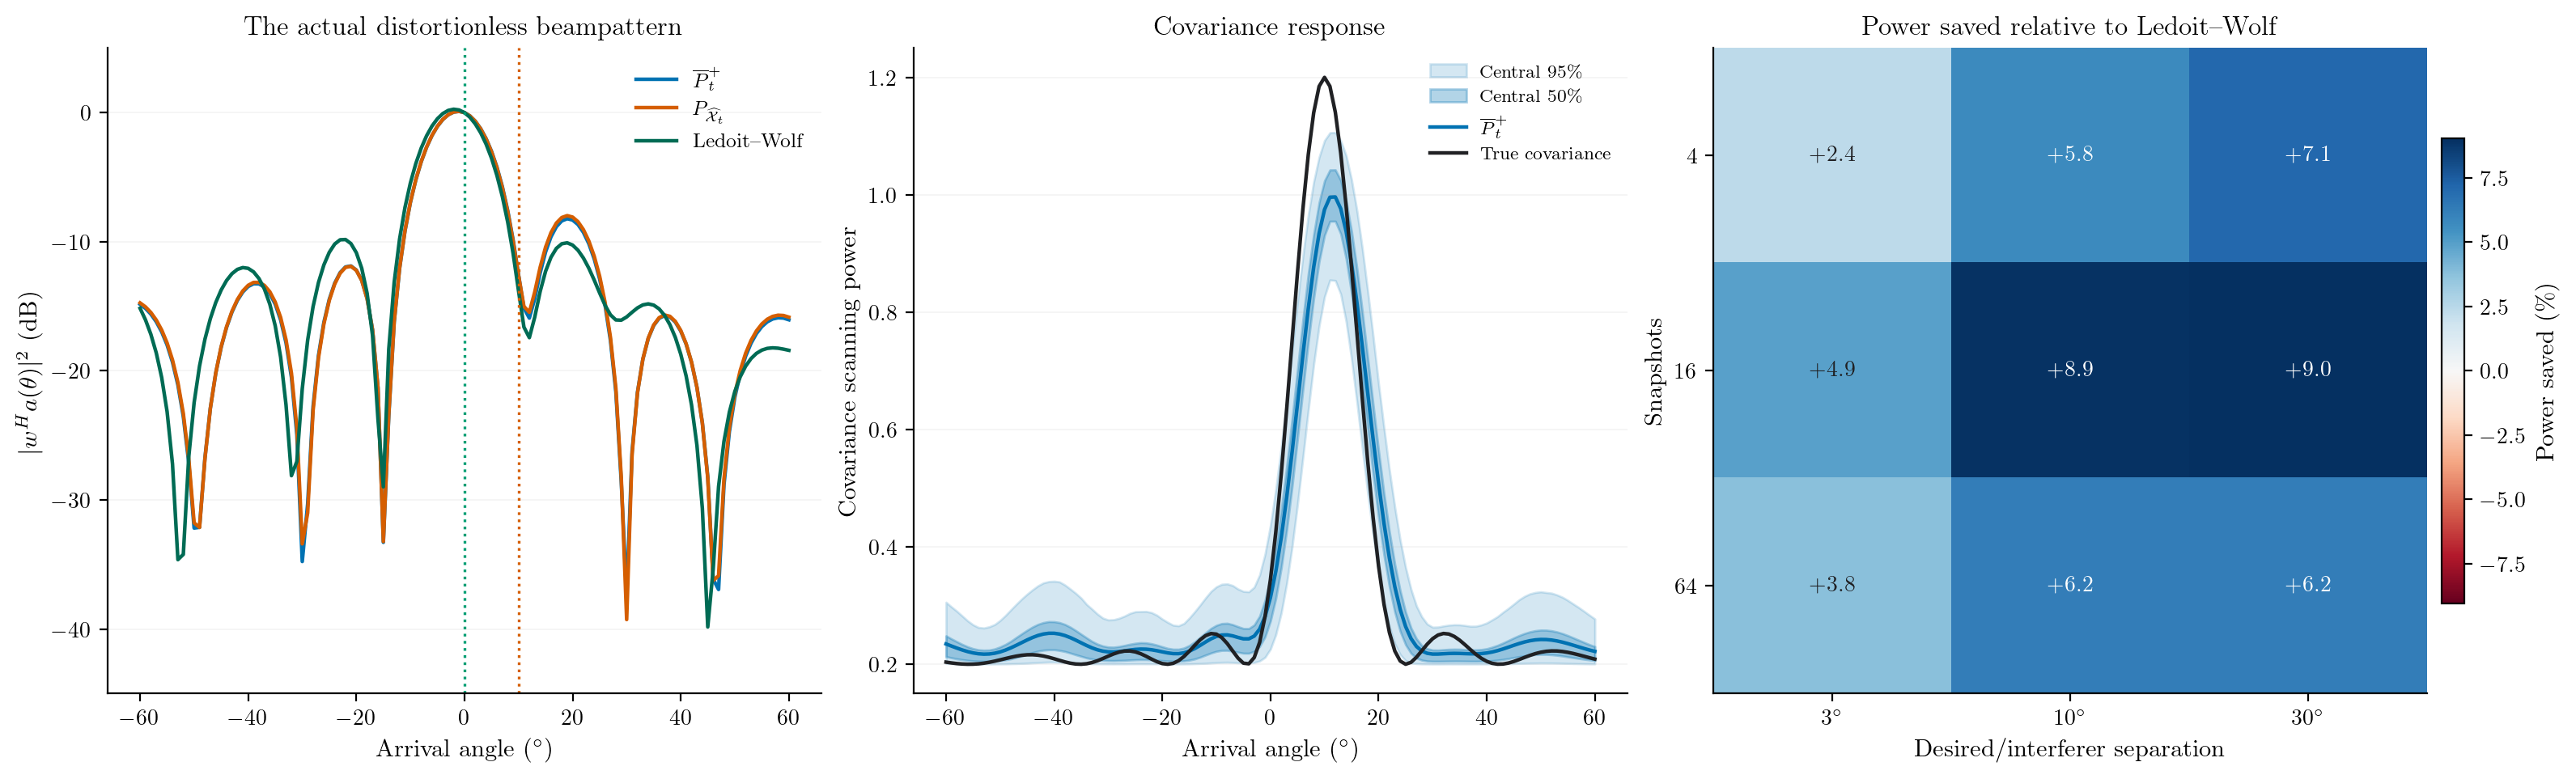

The actual weight beampattern and the uncertain covariance scanning response are different quantities. The middle bands are pointwise central posterior 50% and 95% intervals, not simultaneous confidence bands. At the exact interferer direction the truth is the support maximum, so a finite central interval excludes that endpoint. The small grid retains every predeclared ULA separation and horizon at $N=8$, $s=0.2$; open circles mark pointwise paired intervals crossing zero.

In [6]:
show('beamforming_05_responses')

## S1. What scales, and what costs extra?

The dense correction has $O(N^2)$ storage and arithmetic. Eigenvector extraction, posterior moments and optional credible reports are separate computations. The scaling study holds spectral span fixed when varying dimension, and retains a separate data-generated case. Rank-one/codimension-one means are not general-rank Grassmann calculations.

Serial warmed timing repeats randomize operation order and record CPU and wall clocks. Whole-stream rows assimilate 64 observations and return one endpoint output; nested component clocks must not be added twice. A mean is needed when choosing a posterior expected-power action, while a costly report can be scheduled less often. Numerical caps and unresolved targets remain in the saved tables.

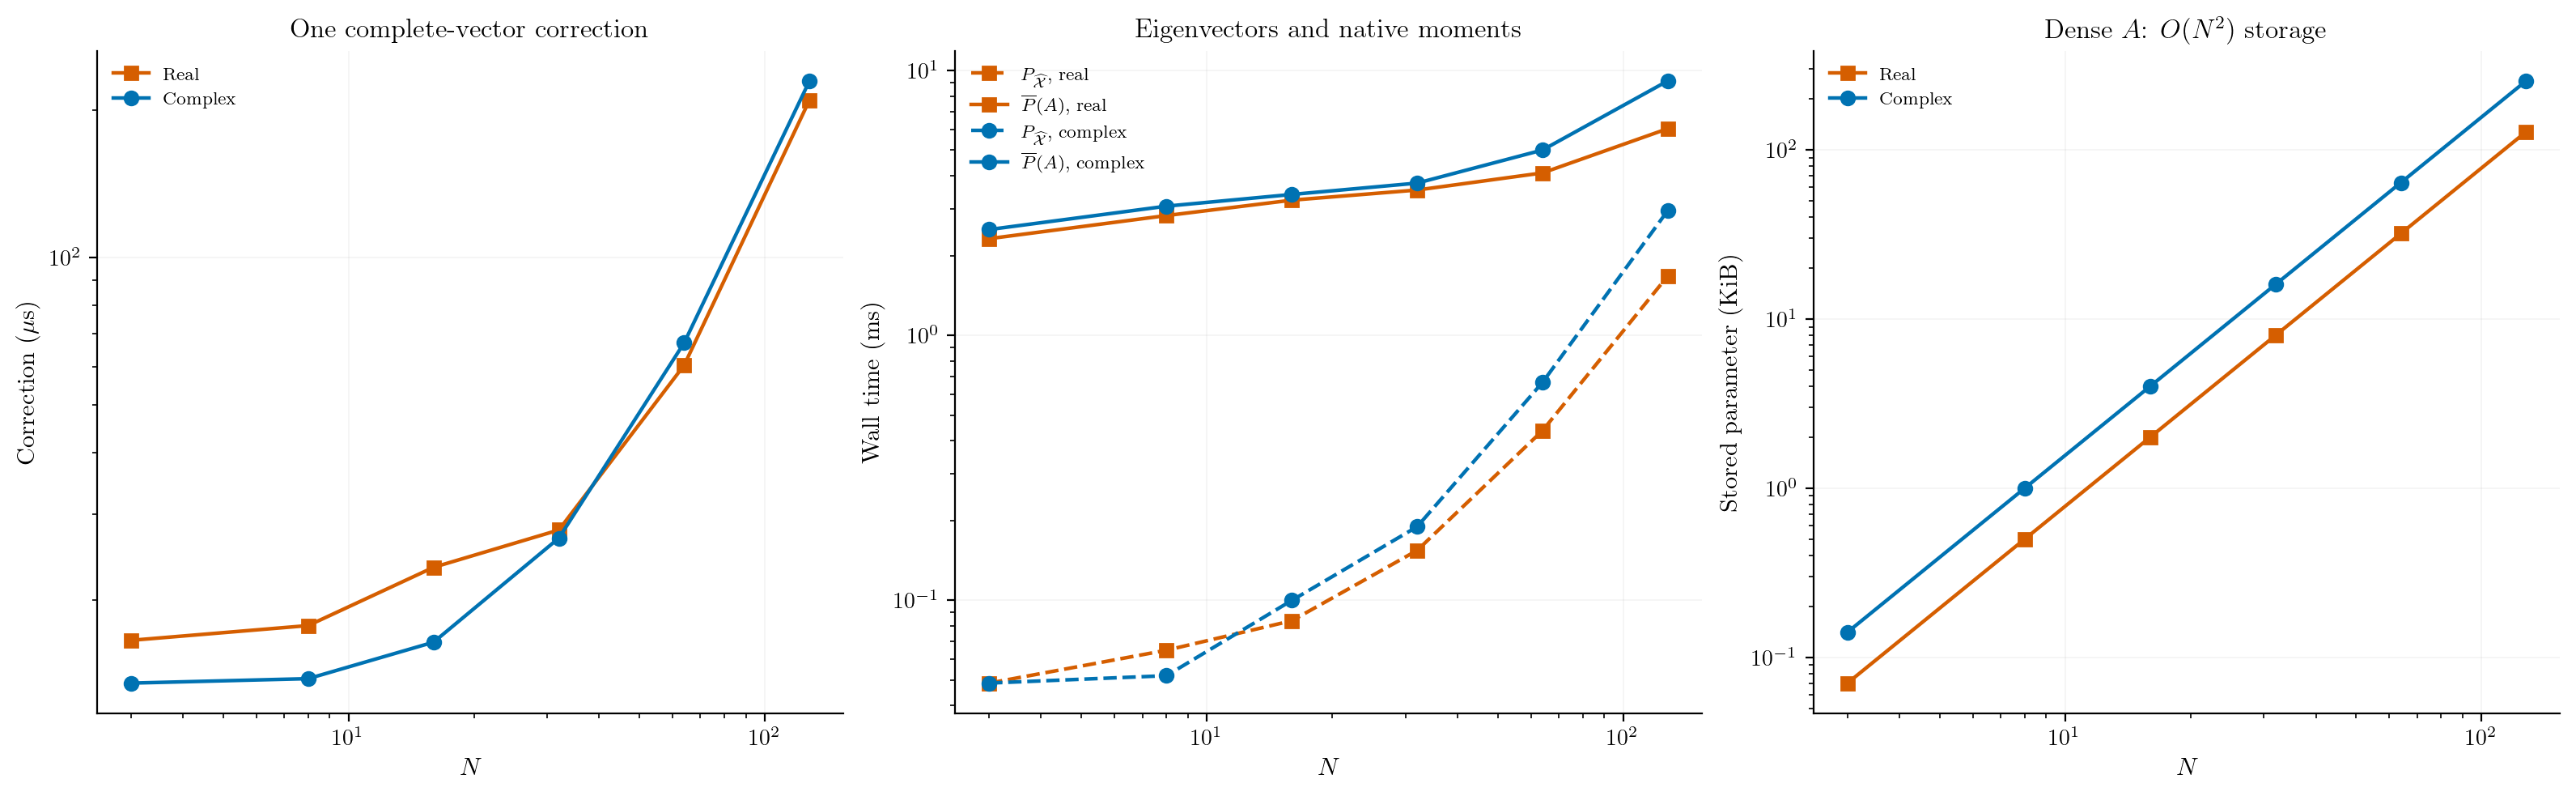

Serial, warmed, randomized-order engineering timings use a common fixed spectral span of 80 to separate dimension from concentration. Correction costs, eigenspace extraction and native means have different scopes; the mean already includes its eigensystem, so clocks are not additive. The real mean uses a common rank-one complement backend rather than the specialized 3D contact integrator. Storage is exact array bytes. More concentrations, endpoint streams, numerical flags and optional report costs are retained in the scaling tables; these points are not complexity proofs or worst-case latency guarantees.

In [7]:
show('beamforming_06_scaling')

## What the independent experiments show

In [8]:
display(Markdown((ROOT / 'results/simulation_redesign/beamforming_summary.md').read_text()))

The $N=8$ paper study keeps Haar signatures and all three ULA separations, both noise powers and all four horizons. For true-covariance output power, the posterior mean records: mode 26 gains/0 losses in 32 cells; matched modal-overlap control 8 gains/4 losses in 32 cells; regularized PCA 6 gains/10 losses in 32 cells; loaded covariance 15 gains/10 losses in 32 cells; Ledoit--Wolf 29 gains/2 losses in 32 cells; GROUSE 32 gains/0 losses in 32 cells. These are paired pointwise 95% intervals, without multiplicity correction. All ties and losses remain. One passive snapshot has exact mean/control equality, so its gain over the mode is regularization, not directional anisotropy.

The designed two-belief example has the same mode and entire distance distribution but different expected-power actions. This proves that mode and radius can omit task-relevant structure; it does not establish a typical-training advantage. Native $N=16$ repeats and serial scaling through $N=128$ are separate, declared cohorts. Sphere images of the complex posterior are fixed-phase three-coordinate density sections, not full or marginal higher-dimensional densities. The practical value of the distribution must survive adaptive covariance baselines and justify its moment/report cost. Scalar credible bands, state-region mass and fixed-state frequentist coverage remain distinct.


## Interpretation and reproducibility

The distribution is useful when its directional predictions or expected decisions improve the actual task enough to justify their cost. The mode already duplicates covariance PCA under matched weights. Conditional expected-power optimality does not promise a universal empirical win, and a fitted ambient prior need not exploit a particular ULA geometry as well as validation-tuned covariance regularization.

Read the [recorded findings](../results/simulation_redesign/findings.md), [protocol and reproduction commands](../results/simulation_redesign/README.md), and [notation and claim scope](../docs/simulation_redesign_notation.md). Complete independent comparisons and numerical flags remain in the component tables. Historical moving-array, unknown-parameter and rank-three results are preserved under their original source manifests; they are not silently presented as results of this redesigned protocol. The [implementation supplement](04_implementation_audit.ipynb) adds the guide checks for Fisher information, revised modal bounds, block EM, pre-observation scores and model mismatch. Its figure IDs and [claim manifest](../results/implementation_audit/claim_manifest.json) identify the evidence and assumptions. No manuscript text is changed.